# 01 - Data acquisition and exploratory data analysis

**MLOps Assignment 01 · Task 1** · Heart Disease UCI (Cleveland) dataset

Goal: understand the data before modelling. This notebook loads the cleaned
dataset produced by `src/data_loader.py`, regenerates the report plots with
`src/eda.py`, and records what the data tells us about modelling choices.

> ✏️ The observation cells below are **drafts based on the plots**. Rewrite them
> in your own words and add anything you notice yourself.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether run from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config
from src.data_loader import load_clean
from src.eda import run_eda

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)

## 1. Load the cleaned data

In [2]:
df = load_clean()
print(f"{df.shape[0]} patients, {len(config.FEATURES)} features + target")
df.head()

303 patients, 13 features + target


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,63.0,145.0,233.0,150.0,2.3,1.0,1.0,1.0,2.0,0.0,3.0,0.0,6.0,0
1,67.0,160.0,286.0,108.0,1.5,1.0,4.0,0.0,2.0,1.0,2.0,3.0,3.0,1
2,67.0,120.0,229.0,129.0,2.6,1.0,4.0,0.0,2.0,1.0,2.0,2.0,7.0,1
3,37.0,130.0,250.0,187.0,3.5,1.0,3.0,0.0,0.0,0.0,3.0,0.0,3.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,2.0,0.0,2.0,0.0,1.0,0.0,3.0,0


## 2. Data dictionary

In [3]:
pd.DataFrame({
    "type": ["numeric" if c in config.NUMERIC_FEATURES else "categorical"
             for c in config.FEATURES],
    "description": [config.FEATURE_DESCRIPTIONS[c] for c in config.FEATURES],
}, index=config.FEATURES)

,type,description
age,numeric,Age in years
trestbps,numeric,Resting blood pressure (mm Hg)
chol,numeric,Serum cholesterol (mg/dl)
thalach,numeric,Maximum heart rate achieved (bpm)
oldpeak,numeric,ST depression induced by exercise relative to rest
sex,categorical,"Sex (1 = male, 0 = female)"
cp,categorical,"Chest pain type (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic)"
fbs,categorical,Fasting blood sugar > 120 mg/dl (1 = true)
restecg,categorical,"Resting ECG result (0 normal, 1 ST-T abnormality, 2 left ventricular hypertrophy)"
exang,categorical,Exercise-induced angina (1 = yes)


## 3. Data quality

In [4]:
missing = df[config.FEATURES].isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["percent"] = (missing["missing"] / len(df) * 100).round(1)
print("Duplicate rows:", int(df.duplicated().sum()))
missing

Duplicate rows: 0


,missing,percent
ca,4,1.3
thal,2,0.7


**Observations (draft - rewrite)**

- 303 patients, 13 features and a binary target.
- Only 6 values are missing in total (`ca`: 4, `thal`: 2, about 1% each), far too
  few to justify dropping rows. They are imputed inside the model pipeline
  (median for numeric, most frequent for categorical), fitted on training data
  only, so no information leaks from validation folds.
- No duplicate rows.

In [5]:
df[config.NUMERIC_FEATURES].describe().round(2)

,age,trestbps,chol,thalach,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


In [6]:
# Regenerate every plot and the summary file under screenshots/eda/
saved = run_eda()


def show(name):
    display(Image(filename=str(config.EDA_DIR / name)))

## 4. Class balance

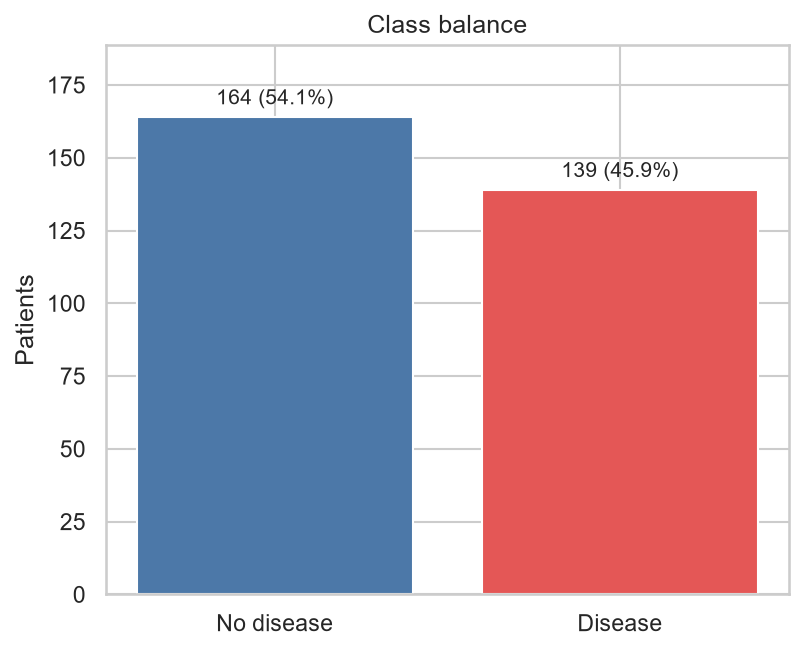

In [7]:
show("class_balance.png")

**Observations (draft - rewrite)**

- 164 patients (54.1%) without disease, 139 (45.9%) with disease: close to
  balanced, so no resampling is needed and accuracy is meaningful.
- Stratified splits and cross-validation keep this ratio in every fold.
- Recall on the disease class matters most clinically (a missed patient costs
  more than a false alarm), so it is reported alongside precision and ROC-AUC.

## 5. Numeric features

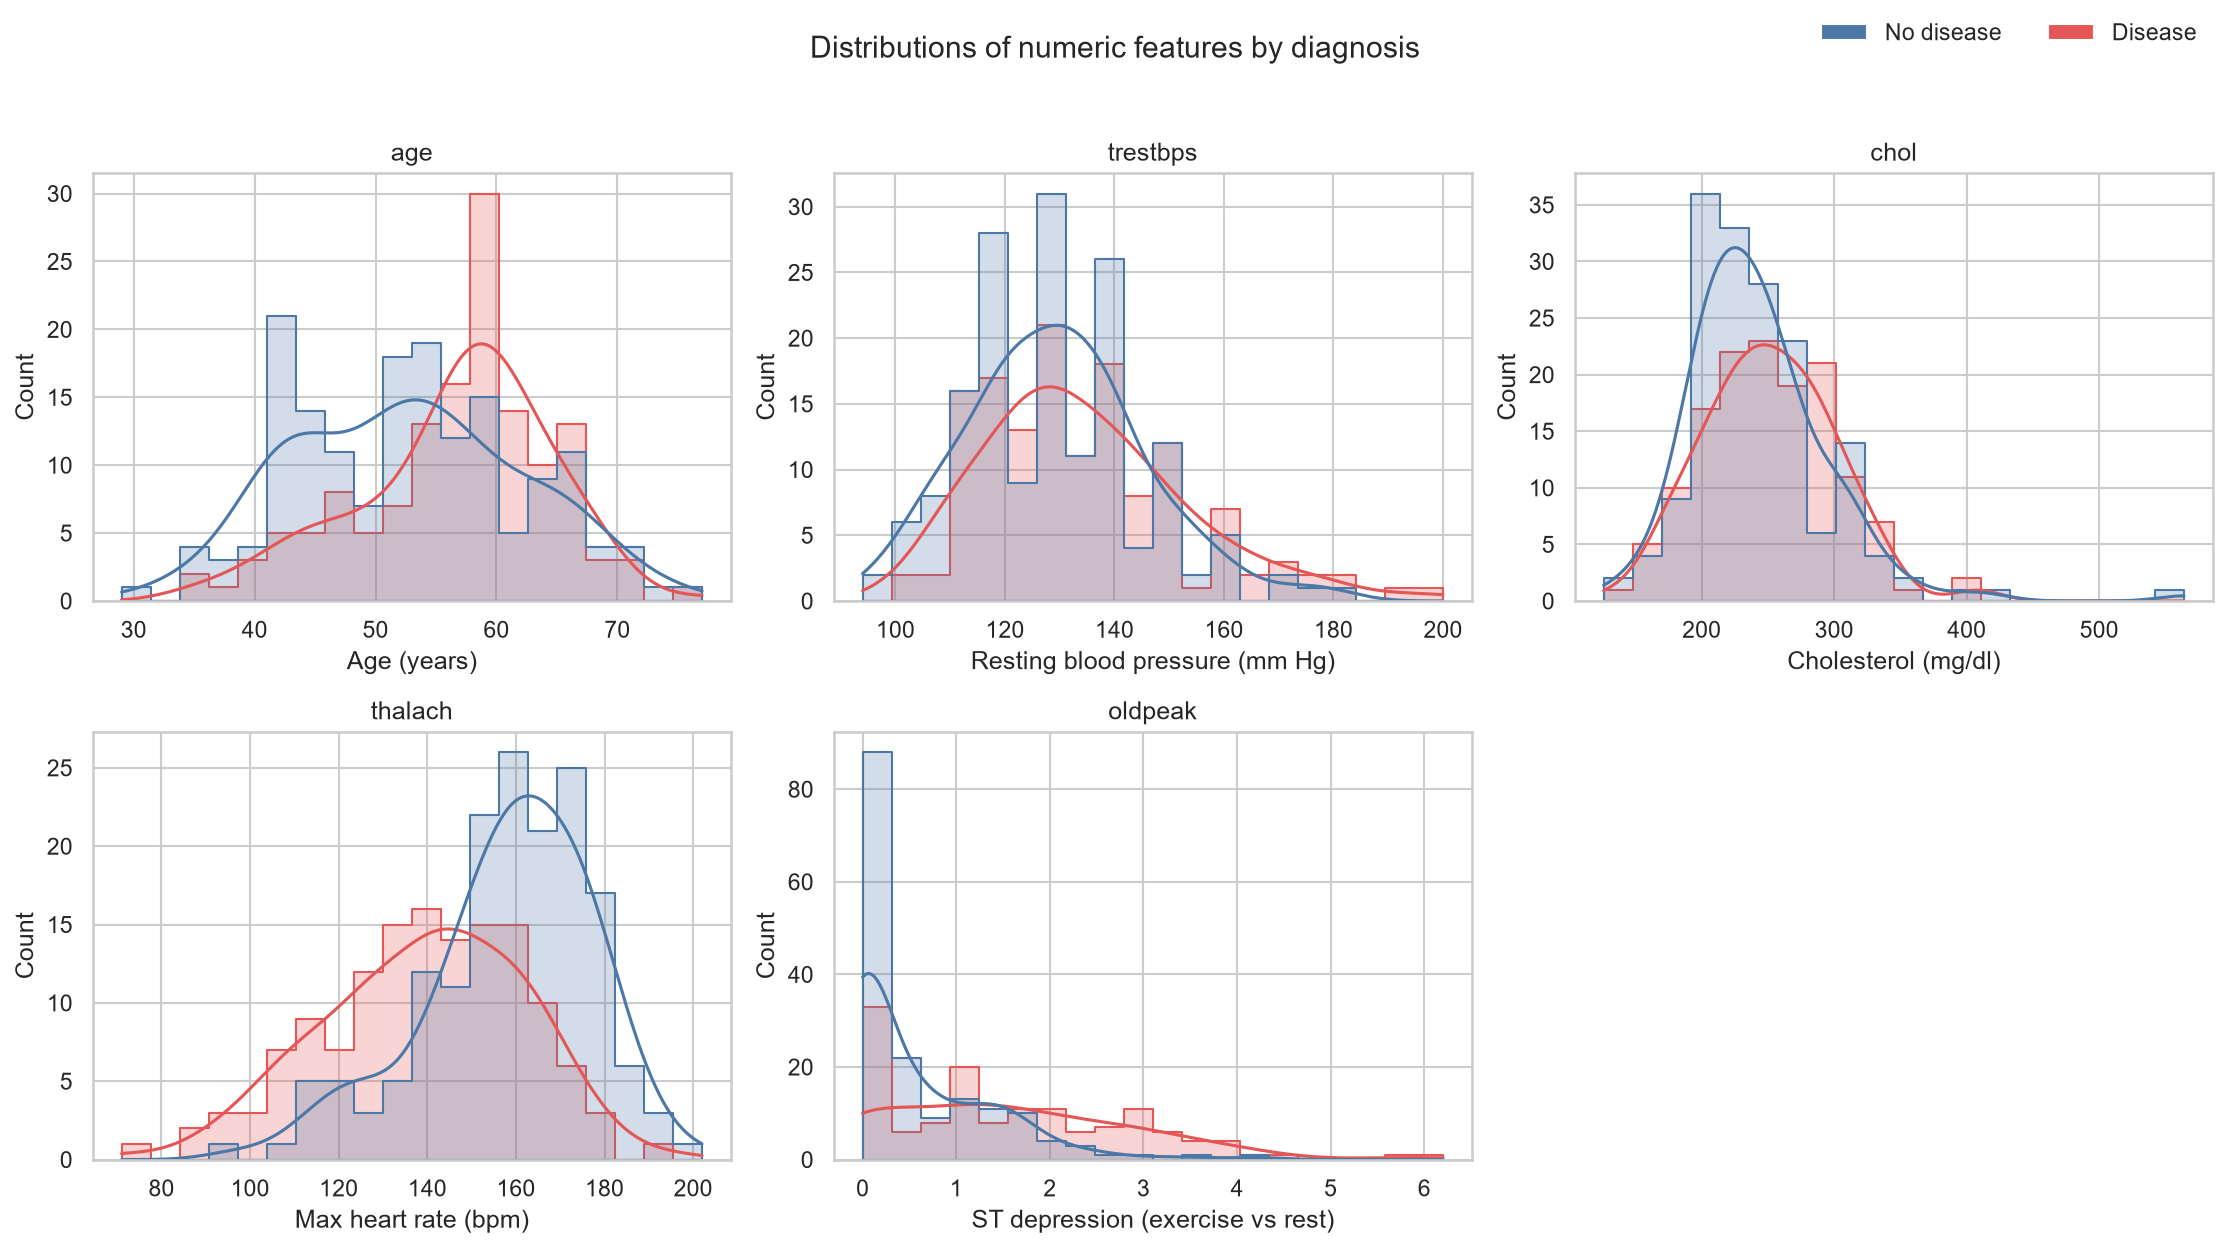

In [8]:
show("numeric_distributions.png")

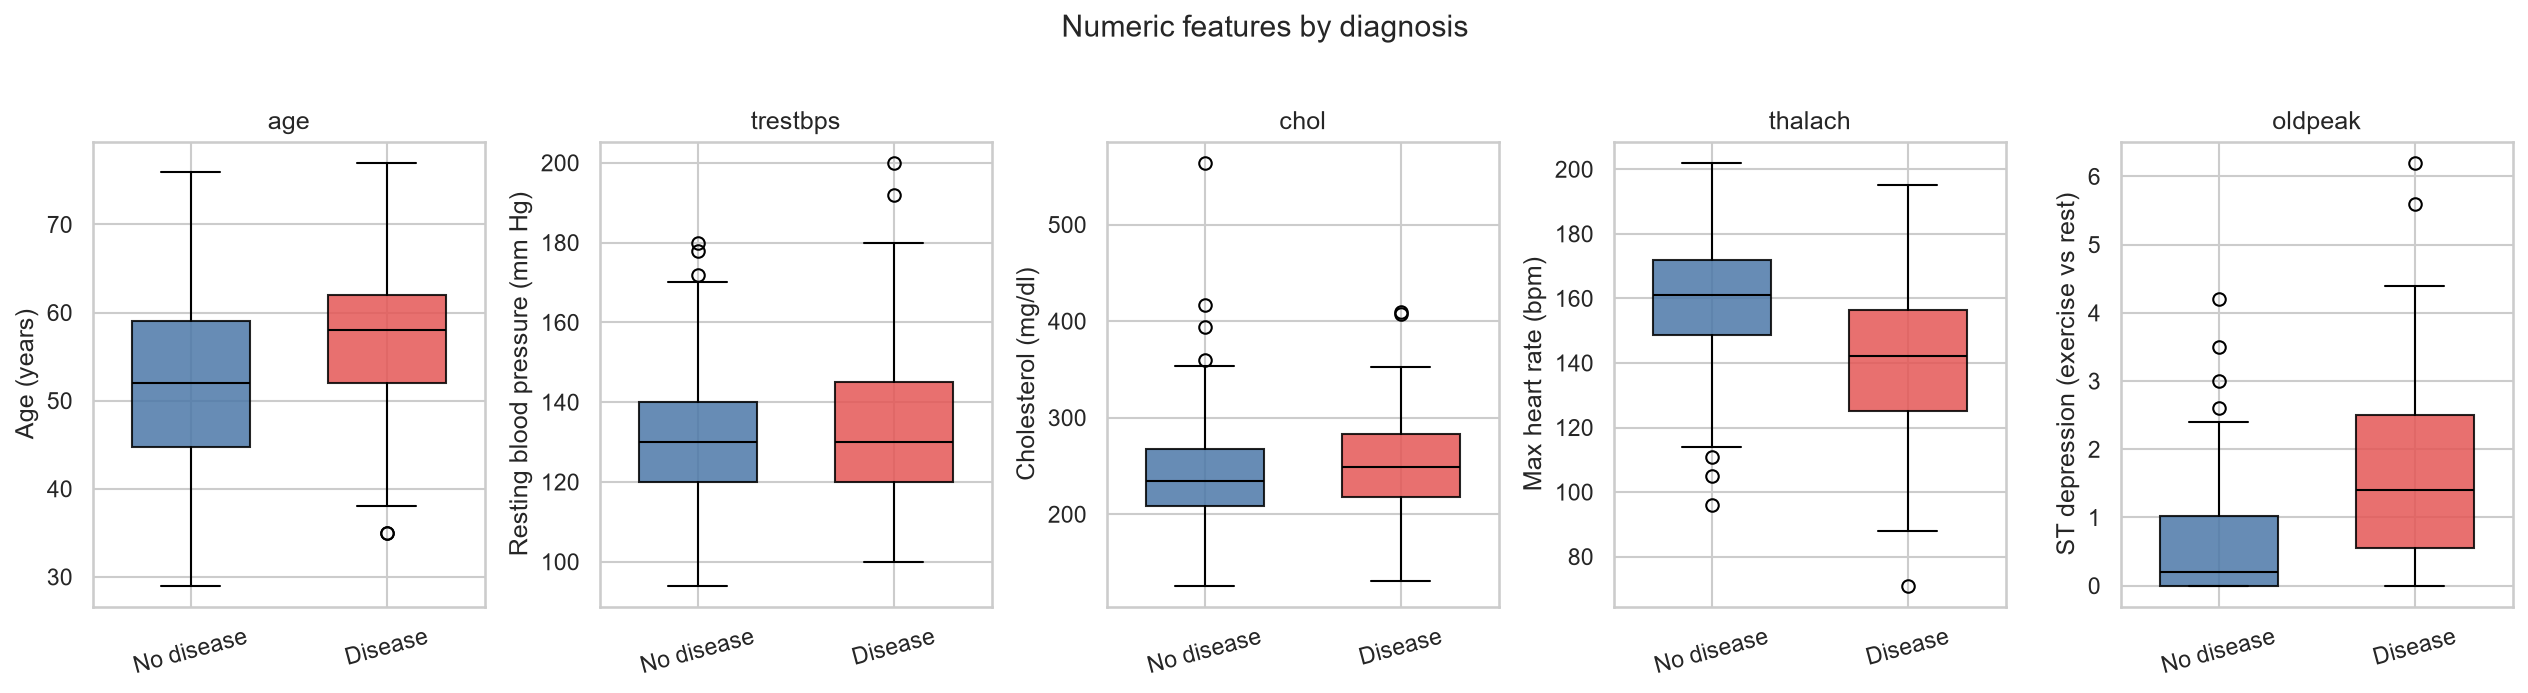

In [9]:
show("numeric_boxplots.png")

**Observations (draft - rewrite; values read approximately from the plots)**

- `thalach` (max heart rate): disease patients reach a clearly lower rate
  (median about 142 vs about 161 bpm). Strongest numeric signal (Spearman -0.42).
- `oldpeak` (ST depression): strongly right-skewed with many zeros; disease
  patients are higher (median about 1.4 vs about 0.2), correlation 0.41. The
  skew motivates trying a log transform.
- `age`: the disease group is older (median about 58 vs about 52), correlation 0.24.
- `chol` and `trestbps`: heavily overlapping distributions and weak signal
  (correlation about 0.12 and 0.13). A few extreme values (cholesterol around
  564, blood pressure 200) are clinically plausible, so they are kept;
  a robust scaler is an option worth comparing.

## 6. Categorical features

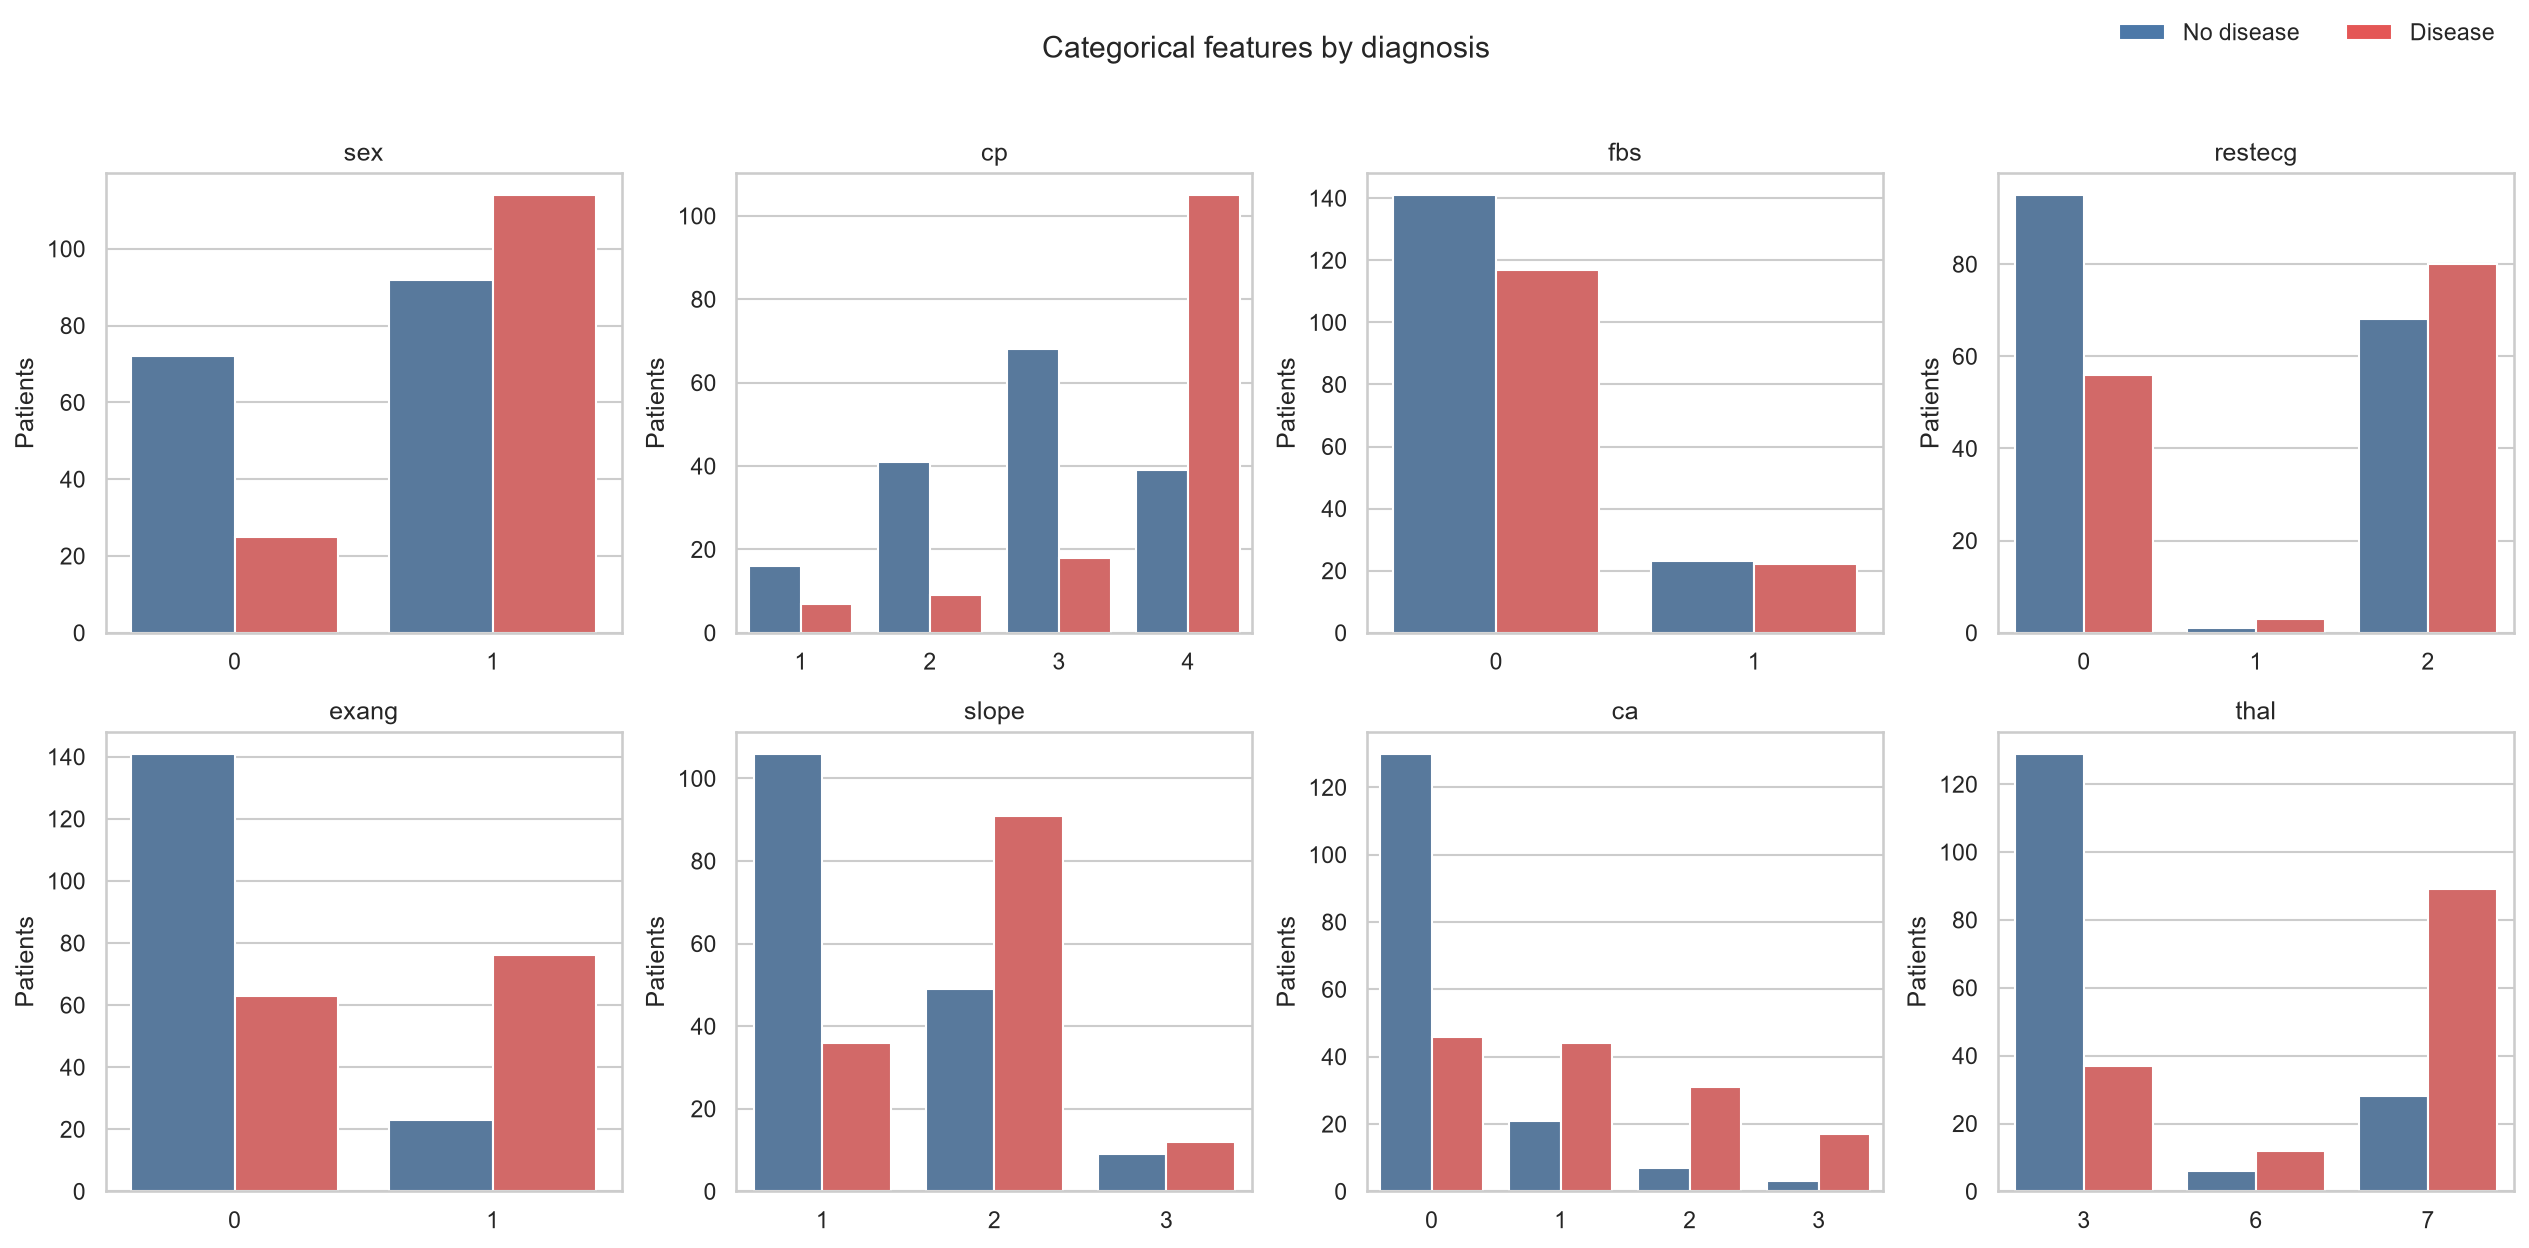

In [10]:
show("categorical_counts.png")

**Observations (draft - rewrite)**

- `thal`: reversible defect (7) is strongly associated with disease, normal (3)
  mostly with no disease.
- `ca`: zero coloured vessels is mostly no disease; one or more is mostly disease.
- `cp`: asymptomatic chest pain (4) is the most common type among disease
  patients, which is counter-intuitive but well known in this dataset.
- `exang` and `slope` show clear but moderate separation. Men make up most of
  the disease group (`sex` = 1).
- `fbs` shows almost no separation, and `restecg` category 1 has only a handful
  of patients, so both are low-value candidates.

## 7. Correlations

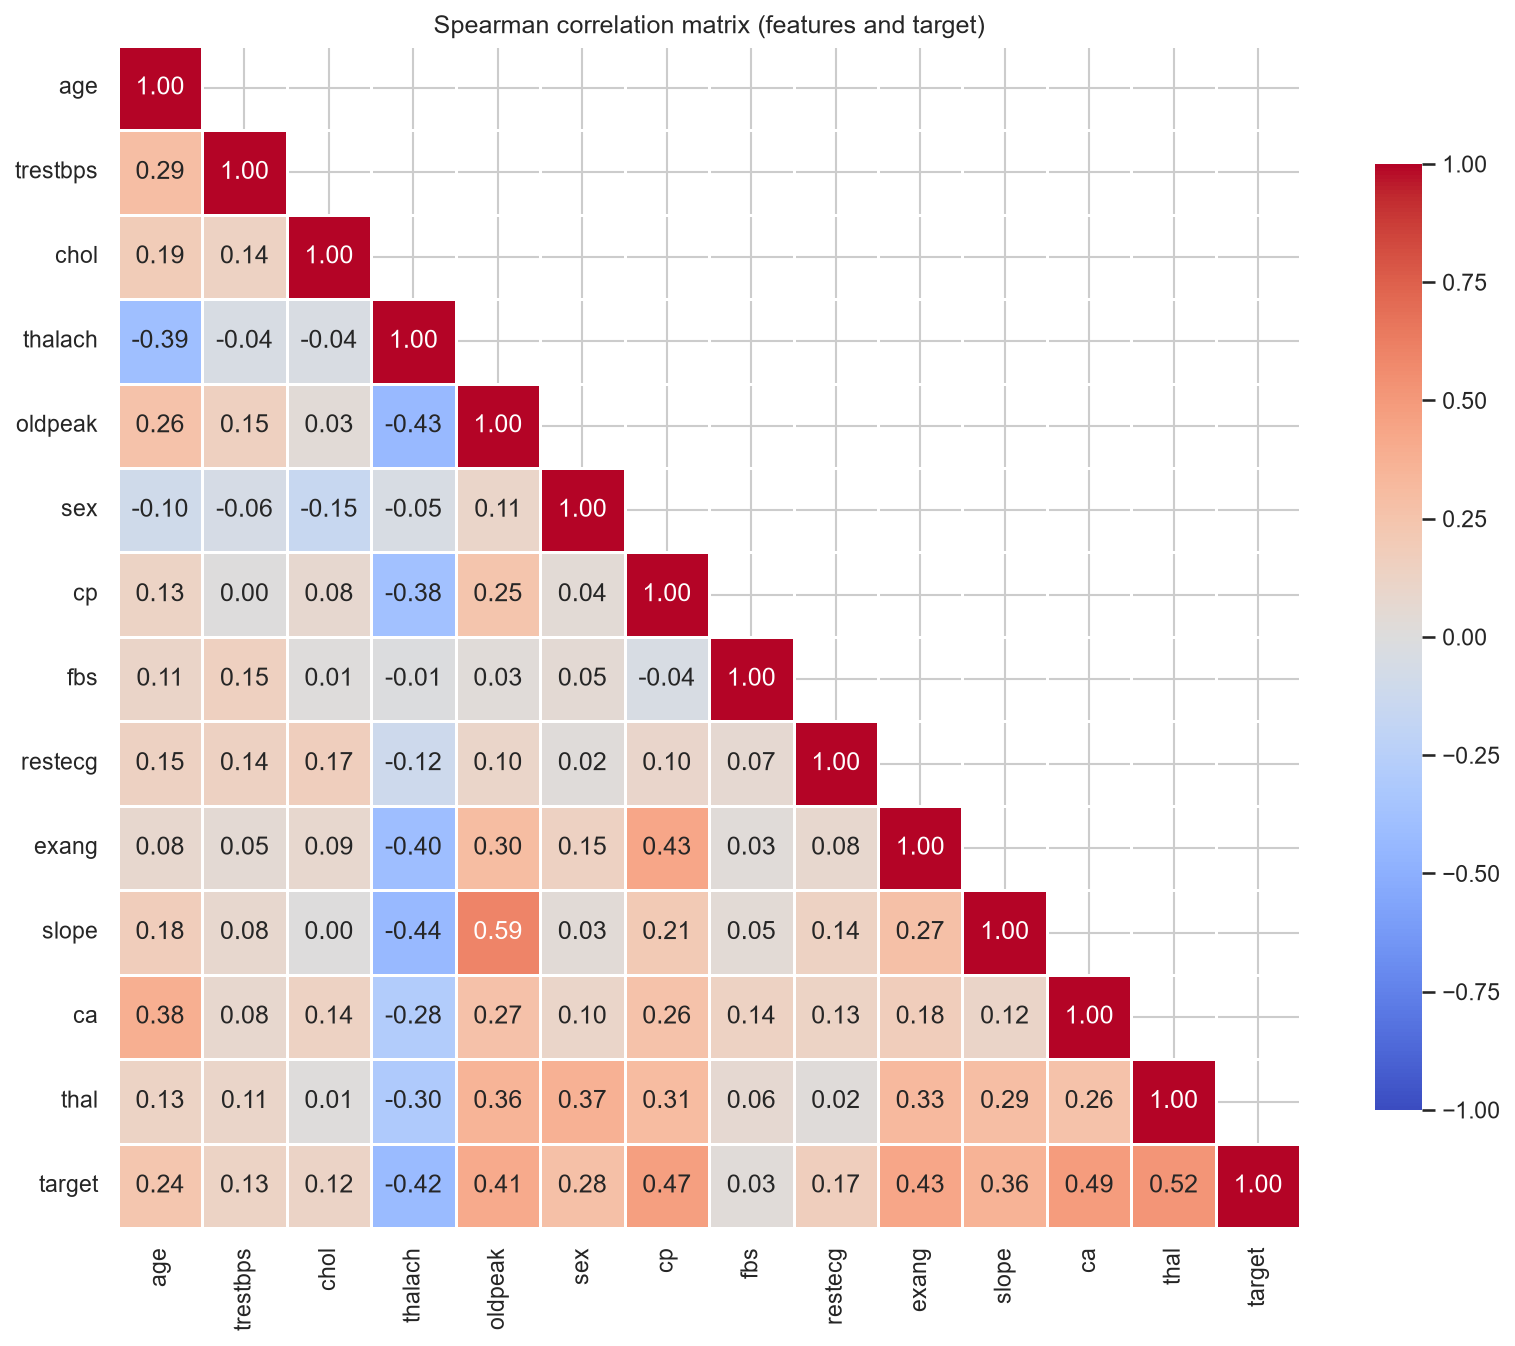

In [11]:
show("correlation_heatmap.png")

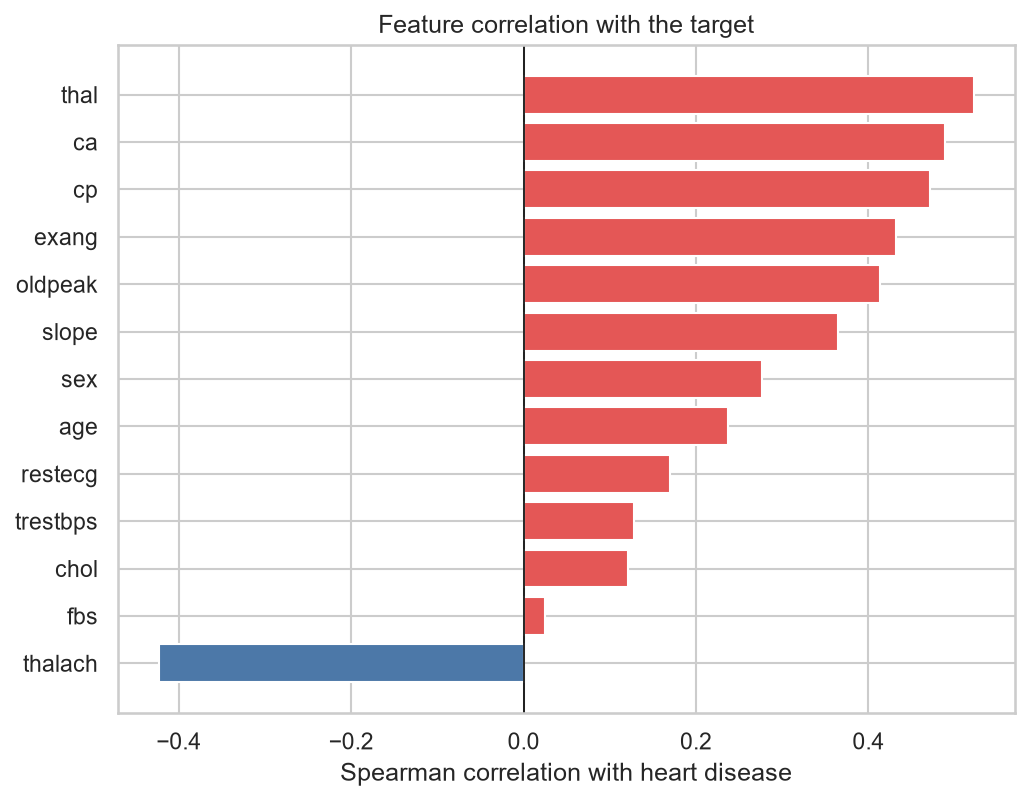

In [12]:
show("target_correlations.png")

**Observations (draft - rewrite)**

- Strongest links with the target: `thal` (0.52), `ca` (0.49), `cp` (0.47),
  `exang` (0.43), `oldpeak` (0.41) and `thalach` (-0.42).
- The highest feature-to-feature correlation is `slope` with `oldpeak` (0.59);
  `thalach` is negatively correlated with `age`, `slope`, `oldpeak`, `exang`
  and `cp` (about -0.38 to -0.44). No pair exceeds 0.6, so multicollinearity is
  moderate and regularised Logistic Regression should cope.
- Caveat: Spearman correlation on integer category codes treats categories as
  ordered, so read these as a rough guide rather than exact effect sizes.

## 8. Implications for modelling

- Use stratified train/test split and stratified cross-validation.
- Impute and scale inside the pipeline (fitted per training fold).
- Scale numeric features (needed for Logistic Regression), one-hot encode categoricals.
- Compare standard vs robust scaling, and with vs without the engineered
  features (heart-rate reserve and log ST depression) as tracked experiments.
- Watch `fbs` and `restecg` during feature-importance analysis.